# Coincidence Validation: GMI and AMSR2

This notebook validates TAT-C's coincidence analyses against the observations of two microwave radiometers on 26 September 2026: the GPM Microwave Imager (GMI), on the Global Precipitation Measurement (GPM) Core Observatory in a 65 deg inclined orbit, and the Advanced Microwave Scanning Radiometer 2 (AMSR2), on GCOM-W in a sun-synchronous orbit. GPM uses GMI as the reference to which it intercalibrates partner radiometers such as AMSR2, from their coincident observations: where the two observe the same place within a short time, here 15 minutes. Their different orbits cross many times a day, but within 15 minutes only where GPM's orbit turns, at high latitudes: on this day, between 55 and 70 deg north and south.

TAT-C finds coincidences in two ways, both validated here against the instruments' recorded sample positions:

1. **Passes.** Does `collect_observations` predict the passes of each instrument over a global grid of points, the basis of the point coincidences? (The scan geometry of both instruments is validated in the [AMSR2](ValidateConicalAMSR2.ipynb) and [GMI](ValidateConicalGMI.ipynb) conical scanner notebooks.)
2. **Coincident observations.** Does `find_coincident_observations` find the points observed by both instruments within 15 minutes, and the time difference between their observations?
3. **Coincident ground track.** Does `find_coincident_ground_track` find the areas observed by both instruments within 15 minutes?

## Reference Data

The Level 1C products of both instruments (`GPM_1CGPMGMI` and `GPM_1CGCOMW1AMSR2`, version 8, from NASA's [GES DISC](https://disc.gsfc.nasa.gov/); free [NASA Earthdata Login](https://urs.earthdata.nasa.gov/) account required) record the time of each scan and the position of each sample: 221 per scan for GMI's low-frequency feed (S1, 10 to 89 GHz) every 1.875 s, and 243 per scan for AMSR2's low-resolution samples (S1) every 1.5 s. The day's orbit files (16 for GMI and 15 for AMSR2) are downloaded once, and the scan times and sample positions are cached in local `data/gmi` and `data/amsr2` directories (shared with the conical scanner notebooks). GMI recorded the whole day; AMSR2's record has a gap of 3.3 hours, during which coincidences are not compared. GPM flew in its forward orientation (`SCorientation` 0) all day, as in the GMI notebook.

In [1]:
import io
from datetime import datetime, timedelta, timezone
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import requests

DAY = datetime(2026, 9, 26, tzinfo=timezone.utc)
PRODUCTS = {
    # instrument: (GES DISC collection, local directory, cached file, swath groups)
    "AMSR2": ("GPM_1CGCOMW1AMSR2", "amsr2", f"amsr2_l1c_s1_{DAY:%Y%m%d}.npz", {"S1": ""}),
    "GMI": ("GPM_1CGPMGMI", "gmi", f"gmi_l1c_{DAY:%Y%m%d}.npz", {"S1": "S1_", "S2": "S2_"}),
}


def download(short_name, cache_file, swaths):
    """Caches the scan times, spacecraft positions, and sample positions of a day of GPM Level 1C files."""
    import earthaccess

    earthaccess.login()
    session = earthaccess.get_requests_https_session()
    granules = requests.get(
        "https://cmr.earthdata.nasa.gov/search/granules.umm_json",
        params={
            "short_name": short_name,
            "version": "08",
            "temporal": f"{DAY:%Y-%m-%d}T00:00:00Z,{DAY:%Y-%m-%d}T23:59:59Z",
            "page_size": 100,
        },
        timeout=120,
    ).json()["items"]
    urls = [next(u["URL"] for u in g["umm"]["RelatedUrls"] if u["URL"].startswith("https://data.gesdisc")) for g in granules]
    parts = []
    for url in urls:
        with h5py.File(io.BytesIO(session.get(url, timeout=900).content)) as f:
            s1 = f["S1"]
            seconds = (
                pd.to_datetime(
                    pd.DataFrame(
                        {
                            "year": s1["ScanTime/Year"][:],
                            "month": s1["ScanTime/Month"][:],
                            "day": s1["ScanTime/DayOfMonth"][:],
                            "hour": s1["ScanTime/Hour"][:],
                            "minute": s1["ScanTime/Minute"][:],
                            "second": s1["ScanTime/Second"][:],
                            "ms": s1["ScanTime/MilliSecond"][:],
                        }
                    ),
                    utc=True,
                )
                - pd.Timestamp(DAY)
            ).dt.total_seconds().to_numpy()
            part = {
                "time": seconds,
                "sc_lat": s1["SCstatus/SClatitude"][:],
                "sc_lon": s1["SCstatus/SClongitude"][:],
                "sc_alt": s1["SCstatus/SCaltitude"][:],
            }
            if "SCorientation" in s1["SCstatus"]:
                part["orientation"] = s1["SCstatus/SCorientation"][:]
            for swath, prefix in swaths.items():
                part[f"{prefix}lat"] = f[f"{swath}/Latitude"][:]
                part[f"{prefix}lon"] = f[f"{swath}/Longitude"][:]
            parts.append(part)
    reduced = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    # keep each scan once (orbit files overlap), in time order, within the day
    _, first = np.unique(reduced["time"], return_index=True)
    keep = first[(reduced["time"][first] >= 0) & (reduced["time"][first] < 86400)]
    np.savez_compressed(cache_file, granules=len(urls), **{k: v[keep] for k, v in reduced.items()})


data = {}
for instrument, (short_name, directory, file_name, swaths) in PRODUCTS.items():
    cache_file = Path("data") / directory / file_name
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    if not cache_file.exists():
        download(short_name, cache_file, swaths)
    data[instrument] = dict(np.load(cache_file))
data["GMI"]["lat"], data["GMI"]["lon"] = data["GMI"]["S1_lat"], data["GMI"]["S1_lon"]  # low-frequency feed


def data_gaps(seconds, threshold=10):
    """Gaps (start, end, s) of more than threshold (s) between scans, including before the first and after the last."""
    i = np.flatnonzero(np.diff(seconds) > threshold)
    gaps = [(seconds[k], seconds[k + 1]) for k in i]
    if seconds[0] > threshold:
        gaps.insert(0, (-np.inf, seconds[0]))
    if seconds[-1] < 86400 - threshold:
        gaps.append((seconds[-1], np.inf))
    return gaps


GAPS = {instrument: data_gaps(d["time"]) for instrument, d in data.items()}
pd.DataFrame(
    {
        instrument: {
            "orbit files": int(d["granules"]),
            "scans": len(d["time"]),
            "samples per scan": d["lat"].shape[1],
            "data gaps (UTC)": ", ".join(
                f"{DAY + timedelta(seconds=max(a, 0)):%H:%M}-{DAY + timedelta(seconds=min(b, 86400)):%H:%M}" for a, b in GAPS[instrument]
            )
            or "none",
        }
        for instrument, d in data.items()
    }
).T

,orbit files,scans,samples per scan,data gaps (UTC)
AMSR2,14,49695,243,08:38-11:55
GMI,16,46081,221,none


## Test 1: Passes

The instruments are modeled with the `ConicalInstrument` parameters fitted in the conical scanner notebooks (cone angle, and the center and half-width of the scanned sector, relative to the inertial velocity, as neither spacecraft is yaw-steered), on orbits from published two-line element sets (TLEs). The TLE of GPM has an epoch 8 days after the analysis day (as in the GMI notebook), and is about 11 km ahead of GPM's recorded position along track, so GMI's predicted observations come about 1.5 s early; the AMSR2 TLE is within about 1 km.

The points form a Fibonacci lattice about 50 km apart, between 75 deg south and north (GMI's swath reaches about 70 deg). A point is observed on a pass when a sample lies within 8 km of it (about half the spacing of the samples along and between scans), at the time of the nearest sample; TAT-C's passes are those of `collect_observations` (at their `epoch`, when the scan crosses the point). Its run of about five minutes is cached in a local `data/coincidence` directory. Observed and predicted passes are paired by point within 60 s, outside the instruments' data gaps.

In [2]:
import pickle
import time

from scipy.spatial import cKDTree
from shapely.geometry import box

from tatc.analysis import collect_observations
from tatc.generation import generate_points_fibonacci_lattice
from tatc.schemas import Attitude, ConicalInstrument, GeneralPerturbationsOrbit, Satellite
from tatc.utils import VelocityFrame

WINDOW = 900  # s, maximum time difference of coincident observations
RADIUS = 8e3  # m, distance within which a sample observes a point
EARTH_RADIUS = 6371.0088e3  # m, mean
# not yaw-steered: the bodies (and the instruments' views) align with the inertial velocity
INERTIAL = Attitude(velocity_frame=VelocityFrame.INERTIAL)
satellites = {
    "AMSR2": Satellite(
        name="GCOM-W",
        attitude=INERTIAL,
        orbit=GeneralPerturbationsOrbit.from_tle(
            [
                "1 38337U 12025A   26277.29678146  .00000240  00000+0  63281-4 0  9990",
                "2 38337  98.2100 216.2278 0001644  77.4488  41.8708 14.57111943764929",
            ]
        ),
        instruments=[
            ConicalInstrument(name="AMSR2", cone_angle=47.564, scan_center_azimuth=0.498, scan_half_width=75.332, along_track_field_of_view=1)
        ],
    ),
    "GMI": Satellite(
        name="GPM",
        attitude=INERTIAL,
        orbit=GeneralPerturbationsOrbit.from_tle(
            [
                "1 39574U 14009C   26277.54227627  .00004528  00000+0  10004-3 0  9997",
                "2 39574  64.9701 301.6724 0010793 268.6572  91.3332 15.45217995714704",
            ]
        ),
        instruments=[
            ConicalInstrument(name="GMI", cone_angle=48.460, scan_center_azimuth=-0.285, scan_half_width=76.031, along_track_field_of_view=1)
        ],
    ),
}
points = generate_points_fibonacci_lattice(50e3, mask=box(-180, -75, 180, 75))
point_index = pd.Series(np.arange(len(points)), index=points.point_id)


def unit(lon, lat):
    """Unit vectors of geodetic coordinates (deg) on a sphere, stacked on the last axis."""
    lon, lat = np.radians(lon), np.radians(lat)
    return np.stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)], axis=-1)


def in_gap(instrument, seconds):
    """Whether times (s) fall within 30 s of a data gap of an instrument."""
    seconds = np.asarray(seconds)
    return np.any([(seconds > a - 30) & (seconds < b + 30) for a, b in GAPS[instrument]] + [np.zeros(seconds.shape, bool)], axis=0)


def true_passes(d):
    """Each pass of an instrument over each point (samples within RADIUS, separated by at least 10 minutes):
    the time (s) of the sample nearest the point."""
    valid = np.all(np.abs(d["lat"]) <= 90, axis=1)
    seconds, lat, lon = d["time"][valid], d["lat"][valid].astype(float), d["lon"][valid].astype(float)
    n = lat.shape[1]
    samples = unit(lon.ravel(), lat.ravel())
    targets = unit(points.geometry.x.to_numpy(), points.geometry.y.to_numpy())
    rows = []
    for k, hits in enumerate(cKDTree(samples).query_ball_point(targets, RADIUS / EARTH_RADIUS, workers=-1)):
        if not hits:
            continue
        hits = np.array(hits)
        t = seconds[hits // n]
        distance = np.linalg.norm(samples[hits] - targets[k], axis=1)
        order = np.argsort(t)
        t, distance = t[order], distance[order]
        bounds = np.r_[0, np.flatnonzero(np.diff(t) > 600) + 1, len(t)]
        rows += [(k, t[a + np.argmin(distance[a:b])]) for a, b in zip(bounds[:-1], bounds[1:])]
    return pd.DataFrame(rows, columns=["point", "seconds"])


truth = {instrument: true_passes(d) for instrument, d in data.items()}
cache = Path("data") / "coincidence" / f"observations_{DAY:%Y%m%d}.pkl"
cache.parent.mkdir(parents=True, exist_ok=True)
if not cache.exists():
    tic = time.perf_counter()
    observations = collect_observations(list(points.geometry), list(satellites.values()), DAY, DAY + timedelta(days=1))
    print(f"collect_observations: {len(observations)} observations of {len(points)} points in {time.perf_counter() - tic:.0f} s")
    observations.to_pickle(cache)
observations = pd.read_pickle(cache)
observations["point"] = point_index.loc[observations.target_hash].to_numpy()
observations["seconds"] = (observations.epoch - pd.Timestamp(DAY)).dt.total_seconds()


def pair(left, right, tolerance):
    """Pairs each row of left with the nearest row of right at the same point within tolerance (s) of time."""
    return pd.merge_asof(
        left.sort_values("seconds"),
        right.rename(columns={"seconds": "paired"}).sort_values("paired"),
        left_on="seconds",
        right_on="paired",
        by="point",
        direction="nearest",
        tolerance=tolerance,
    )


rows = {}
for instrument in data:
    observed = truth[instrument][~in_gap(instrument, truth[instrument].seconds)]
    predicted = observations[observations.instrument == instrument][["point", "seconds"]]
    predicted = predicted[~in_gap(instrument, predicted.seconds)]
    forward, backward = pair(observed, predicted, 60), pair(predicted, observed, 60)
    offset = (forward.paired - forward.seconds).dropna()
    rows[instrument] = {
        "observed passes": len(observed),
        "predicted": len(predicted),
        "observed passes predicted (%)": 100 * forward.paired.notna().mean(),
        "predicted passes observed (%)": 100 * backward.paired.notna().mean(),
        "time offset, median (s)": offset.median(),
        "95% |time offset| (s)": offset.abs().quantile(0.95),
    }
print(f"{len(points)} points; observations outside the instruments' data gaps:")
pd.DataFrame(rows).T.round(2)

250925 points; observations outside the instruments' data gaps:


,observed passes,predicted,observed passes predicted (%),predicted passes observed (%),"time offset, median (s)",95% |time offset| (s)
AMSR2,370748.0,367886.0,99.23,100.0,0.01,1.57
GMI,313805.0,309418.0,98.60,100.0,-1.51,2.49


Outside AMSR2's data gap, every pass TAT-C predicts was observed, and TAT-C predicts 99.2% of AMSR2's and 98.6% of GMI's observed passes; the others are at the edges of the swaths, where the outermost samples lie within 8 km of points just outside TAT-C's swath. GMI's predicted passes come 1.5 s early (median), as expected from its TLE, and AMSR2's within 0.01 s; 95% are within 2.5 s (GMI) and 1.6 s (AMSR2).

## Test 2: Coincident Observations

The true coincidences are the pairs of a GMI pass and an AMSR2 pass over the same point within 15 minutes of each other. `find_coincident_observations` widens each observation period by half of the maximum time difference before and after, and reports each period during which the widened periods of both satellites overlap. Each true coincidence is paired with the nearest coincident observation of the same point within 60 s, from the epochs of the GMI and AMSR2 observations that contribute to it.

The observations of a `ConicalInstrument` are not instantaneous, however: their period (`start` to `end`) is the time the point spends inside the circle the cone traces on the ground, while their `epoch` is the time the scan crosses it. `find_coincident_observations` is therefore run twice: comparing the observations' periods (the default), and with `instantaneous=True`, comparing their epochs, in which case each coincident observation spans the epochs of its contributors, from the first to the last (so that its duration is their time difference).

In [3]:
from tatc.analysis import find_coincident_observations

# true coincidences: pairs of passes over a point within WINDOW of each other, outside the data gaps
true_pairs = truth["GMI"].merge(truth["AMSR2"], on="point", suffixes=("_gmi", "_amsr2"))
true_pairs["dt"] = true_pairs.seconds_gmi - true_pairs.seconds_amsr2
true_pairs = true_pairs[(true_pairs.dt.abs() <= WINDOW) & ~in_gap("AMSR2", true_pairs.seconds_amsr2) & ~in_gap("GMI", true_pairs.seconds_gmi)]
true_pairs["seconds"] = (true_pairs.seconds_gmi + true_pairs.seconds_amsr2) / 2


def coincidences(instantaneous):
    """Coincident observations of pairs of satellites within WINDOW (of their periods, or their epochs if
    instantaneous), with the epochs (s) of the GMI and AMSR2 observations that contribute to each (whose widened
    periods, or epochs, overlap the coincident period)."""
    tic = time.perf_counter()
    found = find_coincident_observations(
        observations, max_time_difference=timedelta(seconds=WINDOW), instantaneous=instantaneous
    )
    elapsed = time.perf_counter() - tic
    frame = observations.assign(start=observations.epoch, end=observations.epoch) if instantaneous else observations
    found["point"] = point_index.loc[found.target_hash].to_numpy()
    half = pd.Timedelta(seconds=WINDOW / 2)
    joined = (
        found[["point", "start", "end"]]
        .reset_index()
        .merge(frame[["point", "instrument", "start", "end", "seconds"]], on="point", suffixes=("", "_observation"))
    )
    joined = joined[(joined.start_observation - half <= joined.end) & (joined.end_observation + half >= joined.start)]
    epochs = joined.groupby(["index", "instrument"]).seconds.first().unstack()
    found["seconds_gmi"], found["seconds_amsr2"] = epochs["GMI"], epochs["AMSR2"]
    found["dt"] = found.seconds_gmi - found.seconds_amsr2
    found["seconds"] = (found.seconds_gmi + found.seconds_amsr2) / 2
    found = found[~in_gap("AMSR2", found.seconds_amsr2) & ~in_gap("GMI", found.seconds_gmi)]
    return found, elapsed


rows = {}
for label, instantaneous in [("observation periods (default)", False), ("instantaneous (epochs)", True)]:
    found, elapsed = coincidences(instantaneous)
    forward = pair(true_pairs[["point", "seconds", "dt"]], found[["point", "seconds", "dt"]].rename(columns={"dt": "dt_found"}), 60)
    backward = pair(found[["point", "seconds", "dt"]], true_pairs[["point", "seconds", "dt"]].rename(columns={"dt": "dt_true"}), 60)
    error = (forward.dt_found - forward.dt).dropna()
    rows[label] = {
        "true coincidences": len(true_pairs),
        "coincident observations": len(found),
        "true coincidences found (%)": 100 * forward.paired.notna().mean(),
        "found coincidences true (%)": 100 * backward.paired.notna().mean(),
        "epochs more than 15 minutes apart": int((found.dt.abs() > WINDOW).sum()),
        "epoch difference, max (s)": found.dt.abs().max(),
        "time difference error, median (s)": error.median(),
        "95% |error| (s)": error.abs().quantile(0.95),
        "unpaired true within 20 s of the limit": int((forward.paired.isna() & (forward.dt.abs() > WINDOW - 20)).sum()),
        "unpaired found within 20 s of the limit": int((backward.paired.isna() & (backward.dt.abs() > WINDOW - 20)).sum()),
        "time (s)": elapsed,
    }
    if instantaneous:
        # each instantaneous coincidence spans the two epochs: its duration is their time difference
        span = (found.end - found.start).dt.total_seconds()
        span_error = (span - found.dt.abs()).abs().max()
durations = (observations.end - observations.start).dt.total_seconds()
print(
    "observation periods: median "
    + ", ".join(f"{i} {durations[observations.instrument == i].median():.0f} s" for i in data)
    + f"; epochs a median {(observations.epoch - observations.start).dt.total_seconds().median():.0f} s after the start"
)
print(f"instantaneous coincidences: duration minus time difference of their epochs, max |x| {span_error:.2e} s")
pd.DataFrame(rows).T.round(2)

observation periods: median AMSR2 234 s, GMI 141 s; epochs a median 8 s after the start
instantaneous coincidences: duration minus time difference of their epochs, max |x| 7.12e-12 s


,true coincidences,coincident observations,true coincidences found (%),found coincidences true (%),epochs more than 15 minutes apart,"epoch difference, max (s)","time difference error, median (s)",95% |error| (s),unpaired true within 20 s of the limit,unpaired found within 20 s of the limit,time (s)
observation periods (default),6554.0,8525.0,97.77,75.17,2116.0,1169.04,-1.03,2.38,6.0,2117.0,2.00
instantaneous (epochs),6554.0,6409.0,97.70,99.91,0.0,899.99,-1.03,2.38,11.0,6.0,1.99


Comparing the observations' periods (the default), `find_coincident_observations` finds 97.8% of the true coincidences, but a quarter of the coincidences it reports (2,116 of 8,525) pair observations whose epochs are more than 15 minutes apart, by up to 19.5 minutes. Their periods last a median of 234 s (AMSR2) and 141 s (GMI) and begin when the scan first reaches the point (a median of 8 s before the epoch), so the periods of two observations come within 15 minutes of each other while their scans of the point do not.

With `instantaneous=True`, the coincidences match: 97.7% of the true coincidences are found, and 99.9% of those found are true (the other 6 are within 20 s of the 15 minute limit, as GMI's 1.5 s timing offset implies), with time differences within 1.0 s (median, the timing offset) and 2.4 s (95%) of the true ones. The true coincidences not found are at the edges of the swaths: 97.7% is the product of the shares of each instrument's passes predicted in Test 1. Each instantaneous coincidence spans exactly the two epochs, so its duration is their time difference. Each run takes about 2 s for the 736,000 observations.

## Test 3: Coincident Ground Track

`collect_ground_track` computes each instrument's footprint (the scanned arc) every 10 s over the day, with an along-track field of view tailored to that time step so that consecutive footprints tile the swath, and `find_coincident_ground_track` finds the pairs of GMI and AMSR2 footprints within 15 minutes of each other that overlap. The union of their overlaps is compared with the points observed by both instruments within 15 minutes (Test 2).

In [4]:
import shapely

from tatc.analysis import collect_ground_track, find_coincident_ground_track
from tatc.constants import EARTH_MEAN_RADIUS
from tatc.utils import compute_along_track_field_of_view

STEP = 10  # s, ground track time step
tracked = []
for instrument, satellite in satellites.items():
    orbit = satellite.orbit.to_gp_orbit()
    # footprints that tile the swath: the along-track field of view tailored to the time step
    width = compute_along_track_field_of_view(
        orbit.get_semimajor_axis() - EARTH_MEAN_RADIUS, STEP, orbit.get_inclination(), eccentricity=orbit.get_eccentricity()
    )
    tracked.append(
        satellite.model_copy(
            update={"instruments": [satellite.instruments[0].model_copy(update={"along_track_field_of_view": width})]}
        )
    )
times = [DAY + timedelta(seconds=STEP * (i + 0.5)) for i in range(86400 // STEP)]
track = collect_ground_track(tracked, times)
seconds = (track.time - pd.Timestamp(DAY)).dt.total_seconds()
track = track[
    ~(((track.instrument == "AMSR2") & in_gap("AMSR2", seconds)) | ((track.instrument == "GMI") & in_gap("GMI", seconds)))
]
tic = time.perf_counter()
footprint_pairs = find_coincident_ground_track(track, max_time_difference=timedelta(seconds=WINDOW))
elapsed = time.perf_counter() - tic
common = shapely.union_all(footprint_pairs.geometry.to_numpy())
shapely.prepare(common)
predicted = shapely.contains_xy(common, points.geometry.x.to_numpy(), points.geometry.y.to_numpy())
observed = np.zeros(len(points), dtype=bool)
observed[true_pairs.point.unique()] = True
print(f"{len(track)} footprints, {len(footprint_pairs)} coincident pairs in {elapsed:.1f} s")
pd.Series(
    {
        "points observed in common": int(observed.sum()),
        "predicted": int(predicted.sum()),
        "both": int((observed & predicted).sum()),
        "observed only": int((observed & ~predicted).sum()),
        "predicted only": int((predicted & ~observed).sum()),
        "observed points predicted (%)": 100 * (observed & predicted).sum() / observed.sum(),
        "predicted points observed (%)": 100 * (observed & predicted).sum() / predicted.sum(),
    }
).round(2)

16087 footprints, 3338 coincident pairs in 1.8 s


points observed in common        5479.00
predicted                        5429.00
both                             5365.00
observed only                     114.00
predicted only                     64.00
observed points predicted (%)      97.92
predicted points observed (%)      98.82
dtype: float64

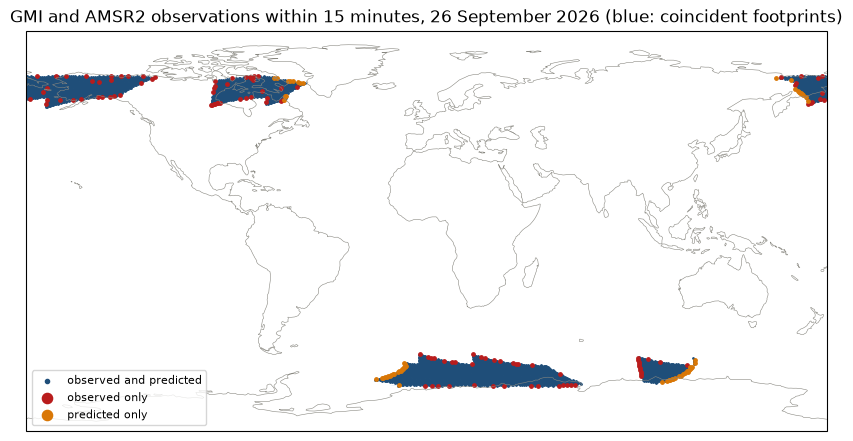

In [5]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_subplot(projection=ccrs.PlateCarree())
ax.coastlines(linewidth=0.4, color="#888780")
ax.set_global()
for geometry in footprint_pairs.geometry.sample(min(len(footprint_pairs), 2000), random_state=0):
    for part in getattr(geometry, "geoms", [geometry]):
        if part.geom_type == "Polygon":
            ax.fill(*part.exterior.xy, color="#93c5fd", alpha=0.5, lw=0, transform=ccrs.PlateCarree())
xy = points.geometry
ax.scatter(xy.x[observed & predicted], xy.y[observed & predicted], s=1, color="#1f4e79", label="observed and predicted", transform=ccrs.PlateCarree())
ax.scatter(xy.x[observed & ~predicted], xy.y[observed & ~predicted], s=6, color="#b91c1c", label="observed only", transform=ccrs.PlateCarree())
ax.scatter(xy.x[predicted & ~observed], xy.y[predicted & ~observed], s=6, color="#d97706", label="predicted only", transform=ccrs.PlateCarree())
ax.set_title("GMI and AMSR2 observations within 15 minutes, 26 September 2026 (blue: coincident footprints)")
ax.legend(loc="lower left", markerscale=3, fontsize=8)
plt.show()

`find_coincident_ground_track` finds 3,338 pairs of footprints that overlap within 15 minutes, in under 2 s. Their union covers 97.9% of the points observed by both instruments within 15 minutes, and 98.8% of the points it covers were observed by both. The differences lie along the edges of the coincident areas: at the edges of the swaths, as in Test 1, and where the time difference reaches 15 minutes, which footprints 10 s apart resolve only to their time step. A footprint's time is instantaneous, so the ground track coincidences need no adjustment.

## Summary

| Test | Result |
| --- | --- |
| 1. Passes | Every predicted pass observed; 98.6% (GMI) and 99.2% (AMSR2) of the observed passes predicted, within 2.5 s and 1.6 s (95%) |
| 2. Coincident observations | Comparing periods (the default), a quarter of the coincident observations pair epochs more than 15 minutes apart (the periods of conical observations last minutes); with `instantaneous=True`, 97.7% of the true coincidences found and 99.9% of those found true, with time differences within 2.4 s (95%) |
| 3. Coincident ground track | 97.9% of the points observed by both instruments within 15 minutes covered by coincident footprints, and 98.8% of the points covered observed by both |

**TAT-C's coincidence analyses are validated against GMI and AMSR2.** With the conical scanner models of the companion notebooks and published orbits, TAT-C predicts where and when GMI and AMSR2 observe the same places within 15 minutes, as points (`find_coincident_observations`) and as areas (`find_coincident_ground_track`), to within the edges of their swaths and a couple of seconds, for a day of observations of a quarter of a million points in seconds.

**Finding: coincidences of observation periods.** `find_coincident_observations` compares the observations' periods (`start` to `end`), not their epochs. For a `ConicalInstrument`, as for a `PointedInstrument`, the period is the time the point spends within reach of the scan, which lasts minutes, while the epoch is the time the scan crosses the point. Coincidences of the samples themselves, as in intercalibration, require comparing the epochs: `find_coincident_observations` does so with `instantaneous=True`, and reports each coincidence from the first contributing epoch to the last, so that its duration is the time difference.

**Next steps:**

1. *Polar coincidences.* Compare coincident observations of two sun-synchronous satellites, such as NOAA-20 and Metop, whose simultaneous nadir overpasses occur near the poles.
2. *Aircraft underflights.* Coincidences of satellites with moving platforms, such as research aircraft, which TAT-C does not yet model.

**Limitations.** This study covers one day and two instruments. GPM's element set is 8 days from the analysis day, which shifts GMI's predicted observations by about 1.5 s, and an instrument observes a point when a sample lies within 8 km of it, which extends the observed swaths slightly beyond TAT-C's.